# Parentheticals: the procedural layer

**Exploratory, not a pipeline.** Task 4 classified the parentheticals into
reactions: applause, laughter, heckling. 29% of all segments matched no
reaction and were set aside as `Kind.OTHER` (20% once the copied blocks are
removed). This notebook looks at what that
third is. Mostly it is the machinery of the chamber:

- votes being signalled and displayed;
- the floor being offered and declined;
- pauses, and who presides;
- ceremonies;
- placards held up in protest.

Everything runs on the **block-deduplicated view** from
`01_parentheticals_data_repairs.ipynb`: 54.5% of cycle 41 and 23.5% of cycle 42
are verbatim copies of earlier blocks. As-is counts are shown where they
differ.

There are no dates or sitting identifiers in these files. Everything below is
counts and sequences, never a timeline.

In [1]:
import json
import re
import subprocess
from collections import Counter
from itertools import groupby
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from parlamonitor.parentheticals import CYCLES, NORMALISATION_VERSION, file_sha256, load_parentheticals, parentheticals_path
from parlamonitor.reactions import _EVENT_SPLIT, Kind, events_in

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)


def rel(path):
    path = Path(path).resolve()
    try:
        return str(path.relative_to(ROOT))
    except ValueError:
        return path.name

## Parameters and provenance

In [2]:
PARAMS = {
    # Seats in the Országgyűlés: 386 until 2014, 199 since. The bound every
    # tally and attendance figure is checked against.
    "seats": {39: 386, 40: 199, 41: 199, 42: 199, 43: 199},
    # Block deduplication, as in notebook 01: window of 10 runs of identical lines.
    "block_window_runs": 10,
}


def block_copy_mask(lines, window=PARAMS["block_window_runs"]):
    # Run-aware block detector from notebook 01: True for every line inside a later
    # verbatim copy of an earlier stretch of `window` runs of identical lines.
    runs = [(line, len(list(group))) for line, group in groupby(lines)]
    seen, copied = set(), [False] * len(runs)
    for i in range(len(runs) - window + 1):
        key = tuple(runs[i:i + window])
        if key in seen:
            copied[i:i + window] = [True] * window
        else:
            seen.add(key)
    return [flag for (_, n), flag in zip(runs, copied) for _ in range(n)]


as_is = {c: load_parentheticals(c)[0] for c in CYCLES}
corpus = {c: [l for l, dup in zip(as_is[c], block_copy_mask(as_is[c])) if not dup] for c in CYCLES}
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print(json.dumps({
    "git_commit": commit,
    "normalisation": NORMALISATION_VERSION,
    "view": "block-dedup",
    "sources": [{"cycle": c, "path": rel(parentheticals_path(c)), "sha256": file_sha256(parentheticals_path(c))[:16],
                 "lines_as_is": len(as_is[c]), "lines_block_dedup": len(corpus[c])} for c in CYCLES],
    "params": PARAMS,
}, indent=1, ensure_ascii=False))

{
 "git_commit": "d06b2c4",
 "normalisation": "strip-soft-hyphen-1",
 "view": "block-dedup",
 "sources": [
  {
   "cycle": 39,
   "path": "data/raw/parantheticals/cycle39-parentheticals.txt",
   "sha256": "852bbebfe9168acd",
   "lines_as_is": 59891,
   "lines_block_dedup": 59891
  },
  {
   "cycle": 40,
   "path": "data/raw/parantheticals/cycle40-parentheticals.txt",
   "sha256": "749b28abb9df40ac",
   "lines_as_is": 50826,
   "lines_block_dedup": 50816
  },
  {
   "cycle": 41,
   "path": "data/raw/parantheticals/cycle41-parentheticals.txt",
   "sha256": "e3523eb1b6a97378",
   "lines_as_is": 101446,
   "lines_block_dedup": 46169
  },
  {
   "cycle": 42,
   "path": "data/raw/parantheticals/cycle42-parentheticals.txt",
   "sha256": "74035ed57eb41b32",
   "lines_as_is": 43978,
   "lines_block_dedup": 33639
  },
  {
   "cycle": 43,
   "path": "data/raw/parantheticals/cycle43-parentheticals.txt",
   "sha256": "2a1f3b86abf6b2bc",
   "lines_as_is": 5794,
   "lines_block_dedup": 5794
  }
 ],
 

## 1. How much is `OTHER`?

`reactions.events_in` splits each line into segments and classifies each
segment. The table counts segments.

In [3]:
def segment_kinds(lines):
    return Counter(e.kind.value for line in lines for e in events_in(line))


rows = []
for c in CYCLES:
    for view, data in (("as-is", as_is), ("block-dedup", corpus)):
        kinds = segment_kinds(data[c])
        total = sum(kinds.values())
        rows.append({"cycle": c, "view": view, "segments": total, "OTHER": kinds["other"],
                     "OTHER share": f"{kinds['other'] / total:.1%}"})
pd.DataFrame(rows).set_index(["cycle", "view"])

segments  OTHER OTHER share
cycle view                                    
39    as-is           67475  11338       16.8%
      block-dedup     67475  11338       16.8%
40    as-is           59136  10971       18.6%
      block-dedup     59126  10971       18.6%
41    as-is          139573  53115       38.1%
      block-dedup     54807  12220       22.3%
42    as-is           55035  17906       32.5%
      block-dedup     40084   9185       22.9%
43    as-is            6988   1293       18.5%
      block-dedup      6988   1293       18.5%

## 2. Extractors

Each extractor is a regular expression over a **whole line**, not a segment.
The sentence splitter breaks `Szünet: 13.05 - 13.14 Elnök: …` at the dash, so
segments are too small for these. Every extractor has a worked example checked
by hand, run as an `assert`.

### 2a. Pauses, with who presided

In [4]:
TIME = r"(\d{1,2})\s?[.:]\s?(\d{2})"
PAUSE = re.compile(rf"^Szünet:\s*{TIME}(?:-?t[óő]l)?\s*(?:[-–?]\s*)?{TIME}(?:-ig| óráig)?\.?\s*(?P<rest>.*)$")
OFFICERS = re.compile(r"\(?(?:Kor)?[Ee]lnök:\s*(?P<chair>.+?)(?:\s+(?:Kor)?[Jj]egyzők?:\s*(?P<notaries>.+?))?\)?$")
HANDOVER = re.compile(r"Az elnöki széket (?P<who>.+?), az Országgyűlés (?P<role>alelnöke|elnöke) foglalja el")


def parse_pause(line):
    m = PAUSE.match(line)
    if not m:
        return None
    h1, m1, h2, m2 = (int(g) for g in m.groups()[:4])
    minutes = (h2 * 60 + m2) - (h1 * 60 + m1)
    rest = m.group("rest").strip()
    officers = OFFICERS.match(rest)
    handover = HANDOVER.search(rest)
    return {
        "start": f"{h1:02d}:{m1:02d}", "end": f"{h2:02d}:{m2:02d}",
        "minutes": minutes if minutes >= 0 else minutes + 24 * 60,
        "crosses_midnight": minutes < 0,
        "chair": (officers.group("chair") if officers else handover.group("who") if handover else None),
        "notaries": officers.group("notaries") if officers else None,
    }


assert parse_pause("Szünet: 13.05 - 13.14 Elnök: Lezsák Sándor Jegyző: Göndör István") == {
    "start": "13:05", "end": "13:14", "minutes": 9, "crosses_midnight": False,
    "chair": "Lezsák Sándor", "notaries": "Göndör István"}
assert parse_pause("Szünet: 22.37-től 22.50-ig Elnök: dr. Latorcai János Jegyző: Göndör István")["minutes"] == 13
assert parse_pause("Szünet: 13.12-14.28 Elnök: Forsthoffer Ágnes")["chair"] == "Forsthoffer Ágnes"
assert parse_pause("Szünet: 11.10 - 11.14 Az elnöki széket dr. Latorcai János, az Országgyűlés alelnöke foglalja el.")["chair"] == "dr. Latorcai János"

pauses, unparsed = [], Counter()
for c in CYCLES:
    for line in corpus[c]:
        if line.startswith("Szünet:"):
            parsed = parse_pause(line)
            if parsed:
                pauses.append({"cycle": c, **parsed})
            else:
                unparsed[c, line] += 1
pauses = pd.DataFrame(pauses)
n_szunet = {c: sum(l.startswith("Szünet:") for l in corpus[c]) for c in CYCLES}
summary = pauses.groupby("cycle").agg(
    parsed=("minutes", "size"), with_chair=("chair", "count"),
    median_minutes=("minutes", "median"), longest=("minutes", "max"))
summary.insert(0, "Szünet lines", pd.Series(n_szunet))
summary

,Szünet lines,parsed,with_chair,median_minutes,longest
cycle,,,,,
39,175,174,170,21.0,165
40,76,74,68,35.5,200
41,95,95,75,6.0,174
42,351,351,340,4.0,407
43,28,28,28,7.0,87


In [5]:
print(f"{sum(unparsed.values())} 'Szünet:' lines did not parse; all of them:")
for (c, line), n in unparsed.most_common():
    print(f"  {c} ×{n}  {line[:110]}")

3 'Szünet:' lines did not parse; all of them:
  39 ×1  Szünet: 17.10 órától-...
  40 ×1  Szünet: 12.49 órától 13.03 óráig Elnök: dr. Latorcai János Jegyzők: dr. Szűcs Lajos és Ikotity István
  40 ×1  Szünet: 14.28 - 14 33 Elnök: Lezsák Sándor Jegyzők: dr. Tiba István és Szávay István


### 2b. Vote tallies, attendance and vote signals

Most votes are announced in the chair's *speech*, which is not in these
files. A tally appears as a stage direction only when the note-taker described
the display board. So this is a **sample of votes, not the record of them**.

When a field is missing it stays `null`. *"48 igen szavazat"* does not say
there were no *nem* votes.

In [6]:
NUM = {"nulla": 0, "egy": 1}
TALLY_CUE = re.compile(r"kijelző|tábl|eredmény|^Szavazás")
TALLY_FIELDS = {"igen": "yes", "nem": "no", "tartózkod": "abstain"}


def parse_tally(line):
    if not TALLY_CUE.search(line):
        return None
    out = {}
    for word, field in TALLY_FIELDS.items():
        m = re.search(rf"(\d+|nulla|egy)\s+{word}", line)
        out[field] = (int(m.group(1)) if m.group(1).isdigit() else NUM[m.group(1)]) if m else None
    return out if any(v is not None for v in out.values()) else None


ATTEND = re.compile(r"jelen van\s+(\d+)(?:,\s*távol van\s+(\d+))?")
SIGNAL = re.compile(r"^(?:(?P<who>[A-ZÁÉÍÓÖŐÚÜŰ].*?)\s+jelzésére|Jelzésre)[:.]$")

assert parse_tally("A kijelzőn megjelenő eredmény: 58 igen, 130 nem, 1 tartózkodás. - Bősz Anett jelzésére:") == {"yes": 58, "no": 130, "abstain": 1}
assert parse_tally("A kijelzőn megjelenő eredmény: 48 igen szavazat.") == {"yes": 48, "no": None, "abstain": None}
assert parse_tally("A táblán megjelenő eredmény: 160 igen, nulla nem, nulla tartózkodás.") == {"yes": 160, "no": 0, "abstain": 0}
assert parse_tally("Novák Előd: 15 igen! - Zsigó Róbert: Végre valaki figyel!") is None  # a heckle, not the board
assert SIGNAL.match("Bóna Zoltán jelzésére:").group("who") == "Bóna Zoltán"
assert SIGNAL.match("Jelzésre:").group("who") is None

tallies, attendance, signals = [], [], Counter()
for c in CYCLES:
    for line in corpus[c]:
        t = parse_tally(line)
        if t:
            tallies.append({"cycle": c, **t, "line": line})
        a = ATTEND.search(line)
        if a:
            attendance.append({"cycle": c, "present": int(a.group(1)), "absent": int(a.group(2)) if a.group(2) else None})
        for piece in _EVENT_SPLIT.split(line):
            s = SIGNAL.match(piece.strip())
            if s:
                signals[c, s.group("who") or "(unnamed: 'Jelzésre:')"] += 1
tallies, attendance = pd.DataFrame(tallies), pd.DataFrame(attendance)
tallies["complete"] = tallies[["yes", "no", "abstain"]].notna().all(axis=1)
tallies["cast"] = tallies[["yes", "no", "abstain"]].sum(axis=1, min_count=1)
pd.DataFrame({
    "tallies": tallies.groupby("cycle").size(),
    "complete": tallies.groupby("cycle")["complete"].sum(),
    "attendance checks": attendance.groupby("cycle").size(),
    "vote signals": pd.Series({c: sum(n for (cc, _), n in signals.items() if cc == c) for c in CYCLES}),
}).fillna(0).astype(int)

,tallies,complete,attendance checks,vote signals
39,11,10,0,1471
40,6,6,0,1762
41,25,20,2,1838
42,20,8,0,1278
43,2,1,1,142


### 2c. Sanity checks that fail loudly

Every figure is checked against the chamber's size for its cycle: 386 seats
before 2014, 199 after. A flat 199 would have rejected eight genuine
cycle-39 votes, such as *316 igen, 41 nem*. That is why the bound is a
per-cycle parameter.

In [7]:
seats = tallies["cycle"].map(PARAMS["seats"])
over = tallies[tallies["cast"] > seats]
assert over.empty, over[["cycle", "yes", "no", "abstain", "line"]]
att_total = attendance["present"] + attendance["absent"].fillna(0)
assert (att_total <= attendance["cycle"].map(PARAMS["seats"])).all()
assert (pauses["minutes"] > 0).all(), pauses[pauses["minutes"] <= 0]
print("all tallies within seats; all attendance within seats; every pause has positive length")
print(f"pauses crossing midnight: {int(pauses['crosses_midnight'].sum())}")
print(f"tallies with a missing field (kept as null, not zero): {int((~tallies['complete']).sum())} of {len(tallies)}")

all tallies within seats; all attendance within seats; every pause has positive length
pauses crossing midnight: 2
tallies with a missing field (kept as null, not zero): 19 of 64


### 2d. The vote signallers

`X jelzésére:` means a vote taken *at X's signal*. The files do not record
what role X holds. The unnamed `Jelzésre:` is far more common than any named
signaller. Cycle 41's `Bóna Zoltán` drops from 8,721 to 81 once the
copies are removed (notebook 01, §3).

In [8]:
signal_table = pd.DataFrame([(c, who, n) for (c, who), n in signals.items()], columns=["cycle", "signaller", "n"])
signal_table.sort_values(["cycle", "n"], ascending=[True, False]).groupby("cycle").head(4).reset_index(drop=True)

,cycle,signaller,n
0,39,(unnamed: 'Jelzésre:'),1307
1,39,Dr. Schiffer András,8
2,39,Dr. Czomba Sándor,7
3,39,Dr. Kontrát Károly,7
4,40,(unnamed: 'Jelzésre:'),1400
5,40,Dr. Völner Pál,21
6,40,Dr. Répássy Róbert,11
7,40,Dr. Kovács Zoltán,11
8,41,(unnamed: 'Jelzésre:'),1359
9,41,Bóna Zoltán,81


### 2e. Who presides

The note-takers record each change of chair: *Az elnöki széket X, az
Országgyűlés alelnöke foglalja el*. Counting handovers gives each deputy
speaker's share of the chairing. It does not give their time in the chair.

In [9]:
handovers = pd.DataFrame(
    [{"cycle": c, "chair": re.sub(r"^dr\.\s+", "", m.group("who")), "role": m.group("role")}
     for c in CYCLES for line in corpus[c] for m in [HANDOVER.search(line)] if m]
)
top = (handovers.groupby(["cycle", "chair"]).size().rename("handovers").reset_index()
       .sort_values(["cycle", "handovers"], ascending=[True, False]))
top["share of cycle"] = (top["handovers"] / top.groupby("cycle")["handovers"].transform("sum")).map("{:.0%}".format)
top.groupby("cycle").head(3).reset_index(drop=True)

,cycle,chair,handovers,share of cycle
0,39,Balczó Zoltán,183,23%
1,39,Jakab István,171,21%
2,39,Latorcai János,164,20%
3,40,Lezsák Sándor,146,21%
4,40,Sneider Tamás,140,21%
5,40,Jakab István,139,20%
6,41,Jakab István,133,24%
7,41,Lezsák Sándor,119,21%
8,41,Latorcai János,113,20%
9,42,Latorcai János,121,28%


### 2f. Sitting ends (cycles 39 and 40 only)

Cycles 39 and 40 record the end of each sitting day: *Az ülésnap 23 óra 5
perckor ért véget*. Cycles 41–43 do not. Endings after midnight are common:
a sitting that ends at 2:18 is plotted after 24:00. This is the only sitting boundary
anywhere in these files. For those two cycles, it would let a per-sitting
analysis be built without a re-export.

In [10]:
END = re.compile(r"Az (?:ünnepi )?ülés(?:nap)? (\d{1,2})(?:\s*óra\s*(\d{1,2})\s*(?:perckor|órakor)|\.(\d{2}) órakor| órakor)")
assert END.search("Az ülésnap 23 óra 5 perckor ért véget.").groups() == ("23", "5", None)
assert END.search("Az ülés 17.45 órakor ért véget.").groups() == ("17", None, "45")

ends = []
for c in CYCLES:
    for line in corpus[c]:
        m = END.search(line)
        if m and "ért véget" in line:
            hour, minute = int(m.group(1)), int(m.group(2) or m.group(3) or 0)
            # A sitting that runs past midnight ends at 0:xx; place it after 23:59.
            hour = hour + 24 if hour < 6 else hour
            ends.append({"cycle": c, "hour": hour + minute / 60})
ends = pd.DataFrame(ends)
end_summary = ends.groupby("cycle")["hour"].describe()[["count", "50%", "max"]].round(2)
end_summary["after midnight"] = ends[ends["hour"] >= 24].groupby("cycle").size()
end_summary

,count,50%,max,after midnight
cycle,,,,
39,267.0,21.03,29.80,61
40,265.0,19.03,26.87,14


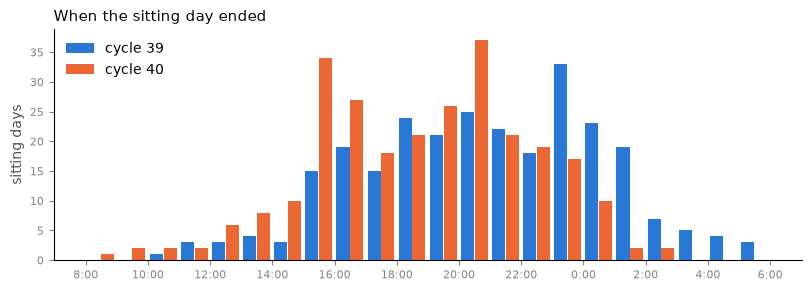

In [11]:
fig, ax = plt.subplots(figsize=(8, 2.8), constrained_layout=True)
bins = list(range(8, 31))
for offset, (c, colour) in enumerate(((39, "#2a78d6"), (40, "#eb6834"))):
    counts = pd.cut(ends.loc[ends.cycle == c, "hour"], bins, right=False).value_counts(sort=False)
    ax.bar([b + 0.06 + offset * 0.44 for b in bins[:-1]], counts.values, width=0.42, align="edge",
           color=colour, label=f"cycle {c}", linewidth=0)
ax.set_xticks(range(8, 31, 2), [f"{h % 24}:00" for h in range(8, 31, 2)])
assert pd.cut(ends["hour"], bins, right=False).notna().all()  # no sitting falls outside the axis
ax.set_ylabel("sitting days", color="#52514e")
ax.legend(frameon=False, loc="upper left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.tick_params(colors="#86847d", labelsize=8)
ax.set_title("When the sitting day ended", loc="left", fontsize=11, color="#0b0b0b")
plt.close(fig)
fig

Cycle 39 sat later. Its median sitting day ended around 21:00, against 19:00 in
cycle 40, and far more of its sitting days ran past midnight. The longest
lasted until nearly 6 a.m.

### 2g. Placards and props

When members hold something up, the note-taker often transcribes what it says,
inside Hungarian quotation marks „…”. These are verbatim protest texts.

In [12]:
PROP_CUE = re.compile(r"felirat|táblá|transzparens|molinó|plakát|felmutat|Felmutatja|kezében|fénykép")
QUOTED = re.compile(r"„([^”]+)”")

props = []
for c in CYCLES:
    for line in corpus[c]:
        if PROP_CUE.search(line):
            props.append({"cycle": c, "texts": QUOTED.findall(line), "line": line})
props = pd.DataFrame(props)
props["has_text"] = props["texts"].map(bool)
print(props.groupby("cycle").agg(lines=("line", "size"), with_quoted_text=("has_text", "sum")).to_string())

       lines  with_quoted_text
cycle                         
39       244                 0
40       167                27
41       186                34
42        84                15
43        17                 0


In [13]:
placard_texts = (props.explode("texts").dropna(subset=["texts"])
                 .groupby(["cycle", "texts"]).size().rename("n").reset_index()
                 .sort_values(["cycle", "n"], ascending=[True, False]))
placard_texts.groupby("cycle").head(5).reset_index(drop=True)

,cycle,texts,n
0,40,"#I stand with CEU. - Heringes Anita szintén egy kör alakú, kék színű jelvényt visel a ruháján, m...",1
1,40,#civilekkel vagyok,1
2,40,"0,9%",1
3,40,A Paks2-hálózat,1
4,40,A nők jogai,1
5,41,FIDESZ,4
6,41,Ellenállás tüntetéssorozat,3
7,41,"Az otthonápolás MUNKA! Lépjünk, hogy léphessenek!",2
8,41,Az otthonápolás munka!,2
9,41,"Ebben a cirkuszban itt lehetek, de a valódiba nem mehetek be?",2


## 3. What the rest of `OTHER` is

Each `OTHER` segment is assigned to the first category whose cue it matches.
One category comes before all the cues:

- **quote continuation**: a sentence that follows a heckle inside the same
  ` - ` piece. `events_in` splits a quote at sentence ends and keeps only the
  first sentence, so *"Dr. Varga László: Mit nevetgéltek ezen? Inkább
  szégyelljétek magatokat!"* leaves its second sentence in `OTHER`.

The cue lists are deliberately readable rather than exhaustive. The
**residual** row is what they miss, and it is shown in full below.

In [14]:
CATEGORIES = [
    ("vote signal", r"(?:^|\s)(?:Jelzésre|jelzésére)[:.]$"),
    ("vote display / tally", r"kijelző|táblán|eredményjelző|\d+\s+(?:igen|nem|tartózkod)|^Szavazás\.?$|Kérem, szavazzanak|szavazógép|kártyá"),
    ("attendance check", r"jelen van|Jelenlét-ellenőrzés|^Megtörténik"),
    ("floor offered, no response", r"Nincs jelentkező|Senki (?:sem|nem) jelentkezik|Nincs (?:ilyen )?jelzés|(?:Nem érkezik|Jelzés nem érkezik)|Nincs észrevétel"),
    ("pause / sitting", r"^Szünet|szünet\.?$|ért véget|^\d{1,2}[.:]\d{2}"),
    ("chair & notaries", r"elnöki széket|jegyzői (?:székben|helyét|helyüket|székét)|Elnök:|Jegyzők?:|levezető elnök"),
    ("time limit & microphone", r"mikrofon|Hangosítás|időkeret|idő leteltét|hozzászólási idő|csengő"),
    ("ceremony & commemoration", r"Himnusz|Szózat|eskü|zászló|köszöntik a választópolgárok|leülnek|felállnak|díszőrség|fanfár|gyertyá|főhajtás|egyperces|adóz(?:nak|ik)|emlékének"),
    ("props & placards", PROP_CUE.pattern + r"|Mutatja"),
    ("movement & seating", r"elfoglalja|vonul|távozik|elhagyja|belép|bejön|kimegy|odamegy|odalép|feláll|leül|helyére|ülésterem|terem közepé|termet|^Mozgás|szólásra emelkedik"),
    ("gesture & aside", r"bólint|int\.$|mutat|tapsol|beszélget|konzultál|súg|nevet|mosolyog|fejét|kezét|kezet fog|gratulál|átad|lapoz|olvas|jegyzetel|telefon|jelnyelvi"),
    ("editorial & artefact", r"^[Ss]ic!?$|^Gy\.$|^Nyomtatott$|^Online$|^\d+a$|^Máté \d|^…$|^\.\.\.$"),
]
CATEGORIES = [(name, re.compile(rx)) for name, rx in CATEGORIES]


def categorise(segment, after_quote):
    if after_quote:
        return "quote continuation"
    for name, rx in CATEGORIES:
        if rx.search(segment):
            return name
    return "residual"


assert categorise("Bóna Zoltán jelzésére:", False) == "vote signal"
assert categorise("Inkább szégyelljétek magatokat!", True) == "quote continuation"
assert categorise("Az elnök kikapcsolja a mikrofont.", False) == "time limit & microphone"

coverage, residual = Counter(), Counter()
for c in CYCLES:
    for line in corpus[c]:
        for piece in _EVENT_SPLIT.split(line):
            after_quote = False
            for event in events_in(piece):
                if event.kind is Kind.OTHER:
                    category = categorise(event.text.strip(), after_quote)
                    coverage[c, category] += 1
                    if category == "residual":
                        residual[event.text.strip()] += 1
                else:
                    after_quote = event.quote is not None

cov = pd.Series(coverage).unstack(0).fillna(0).astype(int)
cov["all cycles"] = cov.sum(axis=1)
cov = cov.sort_values("all cycles", ascending=False)
cov["share"] = (cov["all cycles"] / cov["all cycles"].sum()).map("{:.1%}".format)
total_other = sum(segment_kinds(corpus[c])["other"] for c in CYCLES)
assert cov["all cycles"].sum() == total_other  # reconciliation: every OTHER segment lands in exactly one row
cov

,39,40,41,42,43,all cycles,share
residual,2430,1218,1999,1135,315,7097,15.8%
quote continuation,1241,1931,1920,1482,193,6767,15.0%
vote signal,1471,1762,1837,1278,143,6491,14.4%
"floor offered, no response",1611,1475,1322,990,69,5467,12.1%
chair & notaries,1115,1109,918,669,58,3869,8.6%
ceremony & commemoration,191,535,1317,851,104,2998,6.7%
editorial & artefact,296,961,604,910,42,2813,6.3%
gesture & aside,725,529,619,403,117,2393,5.3%
pause / sitting,827,546,388,576,37,2374,5.3%
movement & seating,489,369,530,373,73,1834,4.1%


In [15]:
print(f"residual: {sum(residual.values()):,} segments, {len(residual):,} distinct. The 30 most frequent:")
pd.DataFrame(residual.most_common(30), columns=["segment", "n"])

residual: 7,097 segments, 5,591 distinct. The 30 most frequent:


,segment,n
0,Veszprém,77
1,Kecskemét,35
2,Szégyen!,33
3,Mikrofon nélkül.,26
4,Mikrofon nélkül:,25
5,Szégyelld magad!,17
6,A Fidesz padsoraiban egy képviselő jelentkezik.,17
7,Pillanatnyi szünetet tart.,16
8,Európai Parlament magyarországi képviselője,16
9,Szabolcs-Szatmár-Bereg megye,16


The residual mixes three things:

- **Textual parentheses that are not stage directions**: place names
  (`Veszprém`, `Kecskemét`, county names) and institutional labels (`EU`,
  `Európai Parlament magyarországi képviselője`). The speeches export keeps
  these in `text_clean` for this reason. The parentheticals exporter does not
  separate them.
- **Bare heckles** (`Szégyen!`, `Így van!`) that follow another event after a
  ` - ` and so have no `Name:` prefix.
- **Interjections the classifier cannot parse**: hyphenated names (§4) and
  names with a middle initial (`Sallai R. Benedek: Úgy van!`).
- A long tail of one-off descriptions.

## 4. Side findings about the Task 4 classifier

These came up while categorising `OTHER`. They are **bugs in
`src/parlamonitor/reactions.py`** that change published counts, so they are
written up here and not fixed on this branch.

In [16]:
UPPER = "A-ZÁÉÍÓÖŐÚÜŰ"
HYPHENATED = re.compile(
    rf"^(?:(?:[Dd]r|[Ii]d|[Ii]fj|[Öö]zv)\.\s+)?(?:[{UPPER}][a-záéíóöőúüű]?\.\s+)?"
    rf"(?P<name>(?:[{UPPER}][\w'’]+\s+)*[{UPPER}][\w'’]*-[{UPPER}]?[\w'’]+(?:\s+[{UPPER}][\w'’-]+){{0,3}}):\s+\S"
)
assert HYPHENATED.match("Dr. Kátai-Németh Vilmos: Igen!").group("name") == "Kátai-Németh Vilmos"

missed, missed_by_cycle = Counter(), Counter()
for c in CYCLES:
    for line in corpus[c]:
        for event in events_in(line):
            if event.kind is Kind.OTHER:
                m = HYPHENATED.match(event.text.strip())
                if m and " " in m.group("name"):
                    missed[m.group("name")] += 1
                    missed_by_cycle[c] += 1
print(f"interjections by hyphenated-surname MPs classified as OTHER: {sum(missed.values()):,} "
      f"by {len(missed)} people; per cycle {dict(sorted(missed_by_cycle.items()))}")
pd.DataFrame(missed.most_common(10), columns=["interjector", "missed interjections"])

interjections by hyphenated-surname MPs classified as OTHER: 1,038 by 22 people; per cycle {39: 270, 40: 14, 41: 529, 42: 201, 43: 24}


,interjector,missed interjections
0,Varga-Damm Andrea,477
1,Gaudi-Nagy Tamás,243
2,Sebián-Petrovszki László,211
3,Kanász-Nagy Máté,25
4,Sáringer-Kenyeres Tamás,14
5,Melléthei-Barna Márton,14
6,Fekete-Győr András,10
7,Turi-Kovács Béla,8
8,Cser-Palkovics András,5
9,Sávolt-Szabó Tünde,5


In [17]:
gy = sum(1 for c in CYCLES for line in corpus[c] for e in events_in(line) if e.text.strip() == "Gy.")
print(f"'Gy.' split off as its own segment: {gy:,} times. The two-letter initial in "
      "'Gy. Németh Erzsébet' is not protected as an abbreviation, so the name is cut.")

'Gy.' split off as its own segment: 457 times. The two-letter initial in 'Gy. Németh Erzsébet' is not protected as an abbreviation, so the name is cut.


1. **Hyphenated surnames are never recognised as interjectors.**
   `_NAMED_INTERJECTION` has no hyphen in its name-token class. Varga-Damm
   Andrea, Gaudi-Nagy Tamás and Sebián-Petrovszki László lose hundreds of
   heckles each from `heckler_scores.csv`. In cycle 43, `Kátai-Németh Vilmos`
   (Mi Hazánk) is missing from the heckle network.
2. **Two-letter initials split the name.** `Gy.` (and `Zs.`, `Sz.`, `Cs.`) is
   cut off as a sentence. The interjection still parses as `Németh Erzsébet`,
   but a *different* `Németh Erzsébet` would merge with her.
3. **Quotes keep only their first sentence.** `Event.quote` stops at the first
   `?`/`!`/`.`, and the rest becomes `OTHER`. Counts are unaffected, but any
   content analysis of `reaction_events.csv`'s `quote` column sees truncated
   heckles. Notebook 03 reassembles them.

## 5. Findings, what to promote, and decisions for you

**Findings**

- 20% of segments are `OTHER` in the block-dedup view. Of those, the largest
  categories are:
  - vote signals (`Jelzésre:`);
  - truncated heckle continuations;
  - the floor being offered and declined;
  - chair and notary changes;
  - ceremonies.
- **Votes recorded as stage directions are a sample.** Most tallies are
  announced in the chair's speech, which these files exclude. Partial tallies
  stay `null` in their missing fields.
- **The chamber-size bound is per cycle.** It is 386 for cycle 39 (eight real
  votes exceed 199) and 199 after that.
- **Sitting-end markers exist for cycles 39–40 only.** They give a per-sitting
  segmentation for those cycles without a re-export.
- **Three classifier bugs** in §4. The hyphenated-name bug changes published
  heckler counts.

**What to promote**

- The extractors (`parse_pause`, `parse_tally`, `SIGNAL`, `HANDOVER`, `END`,
  `PROP_CUE`) → a new `src/parlamonitor/procedure.py`, with these asserts as
  doctests. This should be a separate module rather than new `Kind`s: these
  are not reactions, and putting them in the reaction taxonomy would change the
  denominator of every Task 4 rate.
- The `OTHER` categoriser → reporting only, not a classifier. Its cue lists
  are first-match and readable, not validated.

**Decisions for you**

- **Fix the three `reactions.py` bugs?** The hyphen fix in particular reorders
  the cycle-39–42 heckler tables and adds a node to the cycle-43 network. It
  should be its own PR, with before/after counts.
- **Textual parentheses in the parentheticals files** (place names, dates,
  `EU`). Filter on load, or leave them for the exporter to fix.
- **Whether the sitting-end segmentation of cycles 39–40 is worth building**
  before a re-export with sitting IDs.